## WELCOME TO WEEK 6

The Epic Finale Week

And

# WELCOME TO THE **M**ODEL **C**ONTEXT **P**ROTOCOL!

And welcome back to OpenAI Agents SDK.

In [1]:
# The imports

from dotenv import load_dotenv
# MCP 서버들에 연결해 도구를 가져오는 클라이언트
from langchain_mcp_adapters.client import MultiServerMCPClient
# 이미 열려 있는 MCP 세션에서 도구 목록을 불러오는 함수
from langchain_mcp_adapters.tools import load_mcp_tools
# 도구를 사용하는 에이전트를 만드는 함수
from langchain.agents import create_agent
from IPython.display import Image, display
import os

In [2]:
load_dotenv(override=True)

True

# Let's use MCP in LangChain

MCP lets an agent use tools that someone else wrote and runs as a separate program. We start a small client, it spawns the server as a subprocess, and the server reports back the tools it offers. Once you can list one server's tools, you can use any of them the same way.

We meet three local servers, then hand a couple to an agent. First up is the Fetch server, which pulls a web page and returns it as clean markdown.

`MultiServerMCPClient` takes a dictionary of servers keyed by name. `get_tools()` starts each server, collects its tools as LangChain tools, and shuts it down again. These run through `uvx` or `npx` and can be slow the first time.

### A quick note for Windows

Launching a local MCP server from a notebook hits one rough edge on Windows. The server writes its startup output to stderr, but inside a Windows Jupyter kernel that stream has no real file handle behind it, so the launch fails with an `io.UnsupportedOperation: fileno` error, while Mac and Linux are unaffected.

The fix is to send the server's stderr to the null device, so it always has somewhere real to write. We do that once in the next cell, which lets every cell below use `MultiServerMCPClient` exactly as the langchain-mcp-adapters documentation describes it. On Mac and Linux it costs nothing beyond keeping the server's startup banner out of the notebook.

In [3]:
# Windows에서 Jupyter 커널로부터 stdio MCP 서버를 실행하면, 서버의 stderr 스트림에 실제 파일
# 디스크립터가 없어서 io.UnsupportedOperation: fileno 예외가 발생하며 종료된다.
# 아래 코드는 서버의 stderr를 널 디바이스로 보내 항상 실제로 기록 가능한 대상을 갖게 만든다.
# 이 처리를 해두면 이후 모든 셀에서 langchain-mcp-adapters 문서에 나온 방식 그대로
# MultiServerMCPClient를 사용할 수 있다. Mac과 Linux에서는 이 문제가 발생하지 않는다.
import functools      # 함수의 인자를 미리 고정한 새 함수를 만들기 위해 사용
import subprocess     # 널 디바이스를 가리키는 DEVNULL 상수를 사용하기 위해 임포트
import langchain_mcp_adapters.sessions  # 패치 대상인 stdio_client를 가져다 쓰는 모듈

# 모듈에 있는 stdio_client를 errlog=subprocess.DEVNULL이 미리 적용된 함수로 교체한다.
# 이후 어댑터 내부에서 stdio_client를 호출할 때마다 서버의 stderr가 널 디바이스로 연결된다.
langchain_mcp_adapters.sessions.stdio_client = functools.partial(
    langchain_mcp_adapters.sessions.stdio_client, errlog=subprocess.DEVNULL
)

# fetch MCP 서버 세팅

In [4]:
# stdio 방식으로 실행할 MCP 서버의 설정을 담은 딕셔너리.
# transport는 서버와 통신하는 방식, command는 실행할 프로그램, args는 그 프로그램에 전달할 인자 목록이다.
# uvx는 패키지를 별도 설치 없이 임시 환경에서 바로 실행하는 uv의 실행기이고,
# mcp-server-fetch는 URL의 내용을 가져오는 기능을 제공하는 MCP 서버다.
fetch_params = {"transport": "stdio", "command": "uvx", "args": ["mcp-server-fetch"]}

# 서버 이름을 키로 하는 딕셔너리를 받아 MCP 클라이언트를 만든다.
# 여기서는 위 설정을 "fetch"라는 이름으로 등록했다.
fetch_client = MultiServerMCPClient({"fetch": fetch_params})

# 등록된 모든 서버에 접속해 도구 목록을 받아오고, 각각을 LangChain 도구 객체로 변환한다.
# 이 호출은 서버 프로세스를 실행해 목록을 받은 뒤 연결을 닫는다.
fetch_tools = await fetch_client.get_tools()

# 셀의 마지막 표현식이므로 받아온 도구 목록이 출력된다.
fetch_tools

[StructuredTool(name='fetch', description='Fetches a URL from the internet and optionally extracts its contents as markdown.\n\nAlthough originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.', args_schema={'description': 'Parameters for fetching a URL.', 'properties': {'url': {'description': 'URL to fetch', 'format': 'uri', 'minLength': 1, 'title': 'Url', 'type': 'string'}, 'max_length': {'default': 5000, 'description': 'Maximum number of characters to return.', 'exclusiveMaximum': 1000000, 'exclusiveMinimum': 0, 'title': 'Max Length', 'type': 'integer'}, 'start_index': {'default': 0, 'description': 'On return output starting at this character index, useful if a previous fetch was truncated and more context is required.', 'minimum': 0, 'title': 'Start Index', 'type': 'integer'}, 'raw': {'default': False, 'description': 'Get th

In [5]:
print(fetch_tools[0].description)

Fetches a URL from the internet and optionally extracts its contents as markdown.

Although originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.


In [6]:
# MCP 도구의 inputSchema는 LangChain 도구로 변환될 때 args_schema에 그대로 담긴다.
fetch_tools[0].args_schema

{'description': 'Parameters for fetching a URL.',
 'properties': {'url': {'description': 'URL to fetch',
   'format': 'uri',
   'minLength': 1,
   'title': 'Url',
   'type': 'string'},
  'max_length': {'default': 5000,
   'description': 'Maximum number of characters to return.',
   'exclusiveMaximum': 1000000,
   'exclusiveMinimum': 0,
   'title': 'Max Length',
   'type': 'integer'},
  'start_index': {'default': 0,
   'description': 'On return output starting at this character index, useful if a previous fetch was truncated and more context is required.',
   'minimum': 0,
   'title': 'Start Index',
   'type': 'integer'},
  'raw': {'default': False,
   'description': 'Get the actual HTML content of the requested page, without simplification.',
   'title': 'Raw',
   'type': 'boolean'}},
 'required': ['url'],
 'title': 'Fetch',
 'type': 'object'}

# Node and Playwright 세팅

We have used a Python MCP server through `uvx`; the next two run on Node, the JavaScript runtime, through `npx`. Two quick checks before we start.

First, Node itself; you want v22 or later. If the cell below fails, install Node with one command:

- **Windows**, in PowerShell: `winget install OpenJS.NodeJS.LTS`
- **Mac**, in Terminal: `brew install node`
- **Linux**, or if neither works for you: see the guide at [setup/SETUP-node.md](../setup/SETUP-node.md)

After installing, quit Cursor completely and start it again, then reopen this notebook and re-run the lab from the top. That full restart matters: a freshly installed Node is invisible to a notebook that was already running, and restarting just the kernel is not enough.

In [7]:
!node --version
!npx --version

v24.15.0
11.12.1


Second, Playwright, Microsoft's browser automation framework. There is nothing to install: `npx` fetches it on demand, and it drives the copy of Chrome already on your machine. Chrome does not need to be running; Playwright launches its own.

The cell below proves the whole chain with no AI involved at all: Node runs Playwright, Playwright opens Chrome, loads Hacker News, and saves a screenshot. The first run takes a little longer while npx downloads the package.

If it complains that Chrome is not found, either install Chrome normally or run `npx playwright install chrome` in a terminal, then try again.

Navigating to https://news.ycombinator.com
Capturing screenshot into playwright_check.png


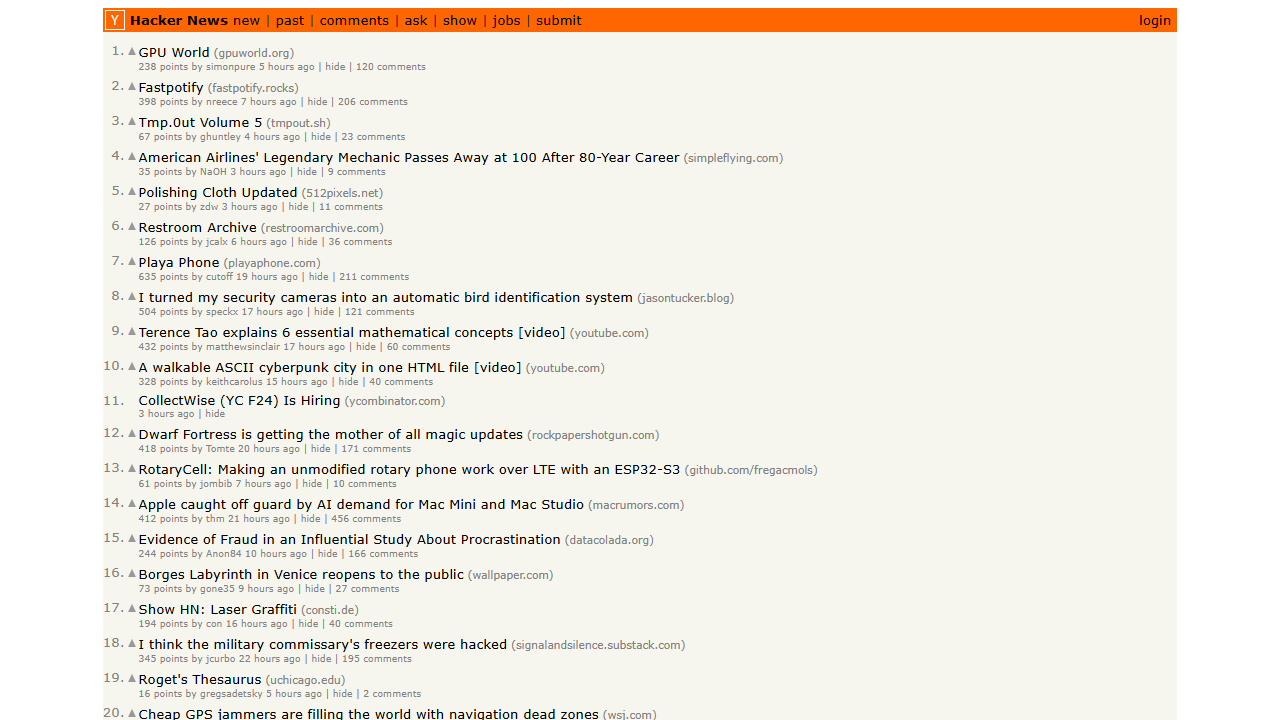

In [8]:
!npx -y playwright@latest screenshot --channel=chrome https://news.ycombinator.com playwright_check.png
display(Image("playwright_check.png"))

## MCP servers - this time Javascript based, with node

Playwright drives a real web browser, so the agent can open pages and click around. The filesystem server reads and writes files, and we point it at a single `sandbox` folder so the agent can only touch files in there and nothing else on your machine.

### If the next cell hangs, see the important troubleshooting at the end of the SETUP-node instructions linked above.

In [9]:
# stdio 방식으로 실행할 MCP 서버의 설정을 담은 딕셔너리.
# npx는 Node.js 패키지를 설치 없이 바로 실행하는 실행기이고,
# @playwright/mcp@latest는 브라우저를 조작하는 기능을 제공하는 MCP 서버의 최신 버전이다.
playwright_params = {"transport": "stdio", "command": "npx", "args": ["@playwright/mcp@latest"]}

# 위 설정을 "playwright"라는 이름으로 등록한 MCP 클라이언트를 만든다.
playwright_client = MultiServerMCPClient({"playwright": playwright_params})

# 서버에 접속해 도구 목록을 받아오고, 각각을 LangChain 도구 객체로 변환한다.
playwright_tools = await playwright_client.get_tools()

# 셀의 마지막 표현식이므로 받아온 도구 목록이 출력된다.
playwright_tools

[StructuredTool(name='browser_close', description='Close the page', args_schema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {}, 'additionalProperties': False}, metadata={'title': 'Close browser', 'readOnlyHint': False, 'destructiveHint': True, 'idempotentHint': None, 'openWorldHint': True}, handle_tool_error=<function _handle_mcp_tool_error at 0x000001AD7BC34360>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x000001AD7C267D80>),
 StructuredTool(name='browser_resize', description='Resize the browser window', args_schema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {'width': {'type': 'number', 'description': 'Width of the browser window'}, 'height': {'type': 'number', 'description': 'Height of the browser window'}}, 'required': ['width', 'height'], 'additionalProperties': False}, metadata={'title': 'Resize browser window',

## snadbox 폴더 만들기

In [10]:
# 현재 작업 디렉터리(os.getcwd())에 "sandbox"를 이어 붙여 경로 문자열을 만들고,
# os.path.abspath로 상대 경로 요소가 없는 절대 경로로 변환한다.
sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))

# 위 경로에 디렉터리를 생성한다.
# exist_ok=True이므로 디렉터리가 이미 있어도 예외가 발생하지 않는다.
os.makedirs(sandbox_path, exist_ok=True)

# 셀의 마지막 표현식이므로 생성된 디렉터리의 절대 경로가 출력된다.
sandbox_path

'c:\\Users\\jino7\\Desktop\\2026_Ai_Python-Source\\LangChain_MCP_26_8_19\\LangChain_MCP\\sandbox'

In [11]:
# 현재 작업 디렉터리에 "sandbox"를 이어 붙인 절대 경로를 만든다.
# 이 경로는 파일시스템 MCP 서버가 접근할 수 있는 유일한 폴더로 사용된다.
sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))

# 해당 경로에 디렉터리를 생성한다. 이미 존재하면 예외를 발생시키지 않고 넘어간다.
os.makedirs(sandbox_path, exist_ok=True)

# stdio 방식으로 실행할 MCP 서버의 설정을 담은 딕셔너리.
# npx는 Node.js 패키지를 실행하는 실행기이고, -y는 설치 여부를 묻는 확인 절차를 건너뛴다.
# @modelcontextprotocol/server-filesystem은 파일 읽기·쓰기 기능을 제공하는 MCP 서버이며,
# 마지막 인자로 넘긴 sandbox_path가 이 서버의 접근 허용 경로가 된다.
files_params = {
    "transport": "stdio",
    "command": "npx",
    "args": ["-y", "@modelcontextprotocol/server-filesystem", sandbox_path],
}

# 위 설정을 "files"라는 이름으로 등록한 MCP 클라이언트를 만든다.
files_client = MultiServerMCPClient({"files": files_params})

# 서버에 접속해 도구 목록을 받아오고, 각각을 LangChain 도구 객체로 변환한다.
file_tools = await files_client.get_tools()

# 셀의 마지막 표현식이므로 받아온 도구 목록이 출력된다.
file_tools

[StructuredTool(name='read_file', description='Read the complete contents of a file as text. DEPRECATED: Use read_text_file instead.', args_schema={'$schema': 'http://json-schema.org/draft-07/schema#', 'type': 'object', 'properties': {'path': {'type': 'string'}, 'tail': {'description': 'If provided, returns only the last N lines of the file', 'type': 'number'}, 'head': {'description': 'If provided, returns only the first N lines of the file', 'type': 'number'}}, 'required': ['path']}, metadata={'title': None, 'readOnlyHint': True, 'destructiveHint': None, 'idempotentHint': None, 'openWorldHint': False}, handle_tool_error=<function _handle_mcp_tool_error at 0x000001AD7BC34360>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x000001AD790489A0>),
 StructuredTool(name='read_text_file', description="Read the complete contents of a file from the file system as text. Handles various text encodings and provides detailed err

# And now, bring on the Agent with Tools!

We hand both servers to a single agent and give it a goal. Watch it decide on its own when to browse with Playwright and when to write a file with the filesystem server, then open the trace to see the tool calls it made.

In [12]:
# 에이전트에게 주는 지시문. 에이전트가 작업할 때 지켜야 할 행동 규칙을 담는다.
INSTRUCTIONS = """
당신은 주어진 지시를 수행하기 위해 인터넷을 탐색합니다.
필요하면 쿠키 동의를 수락하고 팝업을 닫으며 진행하세요.
어떤 웹사이트에서 원하는 정보를 얻지 못하면 다른 사이트를 시도하세요.
과제를 해결할 때까지 여러 선택지와 사이트를 바꿔가며 끈질기게 시도하세요.
파일을 작성해야 할 때는 반드시 sandbox/ 폴더 안에만 작성하세요.
"""

# 에이전트에게 전달할 실제 작업 내용.
TASK = "바노피 파이(Banoffee Pie)의 훌륭한 레시피를 찾은 뒤, 마크다운으로 요약해서 banoffee.md 파일에 저장하세요."


# 파일시스템 서버와 브라우저 서버를 하나의 클라이언트에 함께 등록한다.
# 딕셔너리의 키가 각 서버를 구분하는 이름이 된다.
client = MultiServerMCPClient({"files": files_params, "browser": playwright_params})

# client.session()은 지정한 서버와의 연결을 블록이 끝날 때까지 유지한다.
# 두 블록을 중첩해 두 서버가 동시에 살아 있는 상태를 만든다.
async with client.session("files") as files_session:
    async with client.session("browser") as browser_session:
        # 각 세션에서 도구 목록을 불러와 하나의 리스트로 합친다.
        # 세션을 넘겨서 불러온 도구는 그 연결을 통해 호출되므로,
        # 여러 번 호출하는 동안 같은 서버 프로세스가 유지된다.
        session_file_tools = await load_mcp_tools(files_session)
        session_browser_tools = await load_mcp_tools(browser_session)
        tools = session_file_tools + session_browser_tools

        # 에이전트를 생성한다.
        # model은 사용할 언어 모델, tools는 에이전트가 호출할 수 있는 도구 목록,
        # system_prompt는 위에서 정의한 지시문, name은 에이전트 식별용 이름이다.
        agent = create_agent(
            model="openai:gpt-5-mini",
            tools=tools,
            system_prompt=INSTRUCTIONS,
            name="investigator",
        )

        # 에이전트에 TASK를 사용자 메시지로 넣어 실행한다.
        # run_name은 이 실행에 붙는 이름이고,
        # recursion_limit은 그래프가 실행할 수 있는 최대 단계 수다.
        # 모델 호출과 도구 호출이 각각 한 단계로 세어지므로 왕복 20회는 40단계에 해당한다.
        result = await agent.ainvoke(
            {"messages": [{"role": "user", "content": TASK}]},
            config={"run_name": "investigate", "recursion_limit": 40},
        )

        # 대화 기록의 마지막 메시지가 에이전트의 최종 응답이다.
        print(result["messages"][-1].content)

요청하신 레시피 요약을 banoffee.md 파일로 저장했습니다.

파일 위치: sandbox/banoffee.md

요약 내용은 BBC Good Food의 Banoffee Pie 레시피를 바탕으로 작성한 한글 마크다운 문서입니다. 더 수정하거나 다른 레시피(예: 시판 과자를 이용한 쉬운 버전 등)를 원하시면 알려주세요.


#  One more thing: a remote MCP server

Every server so far has been local: we gave the connection a command, the client spawned the server as a subprocess on your machine, and they talked over stdin and stdout. Plenty of MCP servers instead run as a hosted service you reach over HTTP. You connect to one of those by setting `transport` to `"http"` and giving a URL, with nothing to spawn and nothing to install.

This is the Context7 teaser from back in Week 2. Context7 is a hosted server that looks up current documentation for libraries, a neat way to hand an agent facts that are newer than its training. We ask a question with no help first, then give the agent Context7 and ask again.

In [ ]:
# stdio 방식과 HTTP 방식은 같은 MultiServerMCPClient로 처리하며, 설정 딕셔너리의
# transport 값만 달라진다. 따라서 원격 서버를 위해 추가로 임포트할 클래스는 없다.
# stdio: {"transport": "stdio", "command": ..., "args": [...]}
# HTTP : {"transport": "http", "url": ...}

In [13]:
# 에이전트에게 전달할 질문 문자열.
# 정확한 답변을 요구하고, 모르는 경우 추측하지 말고 모른다고 답하도록 조건을 함께 지시한다.
question = """
2026년 OpenAI Agents SDK에 추가된 SandboxAgents 기능에서 Manifest 객체는 무엇을 위한 것인가요?
정확하게 답하세요. 답을 모른다면 추측하지 말고, 모른다고 말하세요.
"""

In [14]:
# 에이전트를 생성한다.
# model은 사용할 언어 모델, system_prompt는 에이전트가 따를 지시문,
# name은 에이전트 식별용 이름이다. 도구는 전달하지 않았다.
agent = create_agent(model="openai:gpt-5-mini", system_prompt="질문에 답하세요.", name="Expert")

# 앞서 정의한 question을 사용자 메시지로 넣어 에이전트를 실행한다.
result = await agent.ainvoke({"messages": [{"role": "user", "content": question}]})

# 대화 기록의 마지막 메시지가 에이전트의 최종 응답이다.
print(result["messages"][-1].content)

모르겠습니다. 제 지식은 2024-06까지로, 2026년의 OpenAI Agents SDK나 그 SandboxAgents 기능 및 Manifest 객체의 목적에 관해서는 알지 못합니다. 추측하지 않겠습니다.

원하시면 다음을 도와드릴 수 있습니다:
- 관련 공식 문서(릴리스 노트, SDK 레퍼런스, GitHub 저장소)의 링크나 해당 문서 일부를 붙여주시면 그 내용을 해석해 정확히 설명해 드리겠습니다.
- 어디서 해당 정보를 찾을지 안내해 드리겠습니다.


In [15]:
# HTTP 방식으로 접속할 MCP 서버의 설정을 담은 딕셔너리.
# transport를 "http"로 지정하면 프로세스를 실행하지 않고 url의 서버에 접속한다.
# timeout은 응답을 기다리는 최대 시간(초)이다.
# Context7은 라이브러리와 프레임워크의 최신 문서를 검색해 제공하는 MCP 서버다.
params = {"transport": "http", "url": "https://mcp.context7.com/mcp", "timeout": 60}

# 위 설정을 "Context7"이라는 이름으로 등록한 MCP 클라이언트를 만든다.
client = MultiServerMCPClient({"Context7": params})

# 서버에 접속해 도구 목록을 받아오고, 각각을 LangChain 도구 객체로 변환한다.
tools = await client.get_tools()

# 에이전트를 생성한다.
# tools에 위에서 받아온 도구를 전달해 에이전트가 Context7의 도구를 사용할 수 있게 한다.
agent = create_agent(
    model="openai:gpt-5-mini",
    tools=tools,
    system_prompt="Context7을 사용해서 질문에 답하세요.",
    name="Expert",
)

# 앞서 정의한 question을 사용자 메시지로 넣어 에이전트를 실행한다.
result = await agent.ainvoke({"messages": [{"role": "user", "content": question}]})

# 대화 기록의 마지막 메시지가 에이전트의 최종 응답이다.
print(result["messages"][-1].content)

Manifest 객체는 Sandbox 세션의 초기 작업공간(워크스페이스)을 정의하기 위한 것입니다. 정확히 말하면 다음을 지정합니다:

- 워크스페이스 루트와 엔트리(entries): 파일(file), 로컬 디렉토리(localDir), git 리포지토리(gitRepo) 등 세션 시작 시 물리화할 파일/디렉터리 항목들  
- 환경 변수(environment): 세션 내에서 사용할 기본 환경 변수들  
- 추가 경로 권한(extraPathGrants): 외부 디렉터리에 대한 읽기/쓰기 권한 및 설명 등 접근 권한 설정

SandboxAgent에서 이 Manifest를 기본(defaultManifest)으로 제공하면, 해당 Manifest에 정의된 초기 상태가 격리된 샌드박스 세션에 materialize 되어 에이전트가 그 환경에서 명령을 실행하고 파일을 수정하게 됩니다.


### Check out the trace

https://smith.langchain.com

### Now take a look at some MCP marketplaces

https://glama.ai/mcp

https://smithery.ai/